In [1]:
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install opencv-python matplotlib pillow numpy

import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator


  Preparing metadata (setup.py) ... done


In [2]:
import pathlib

CKPT = "sam_vit_b_01ec64.pth"
if not pathlib.Path(CKPT).exists():
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry["vit_b"](checkpoint=CKPT)
sam.to(device)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.90,
    min_mask_region_area=400
)

print("SAM loaded on", device)


SAM loaded on cuda


Saving MAX_3798.JPG to MAX_3798.JPG


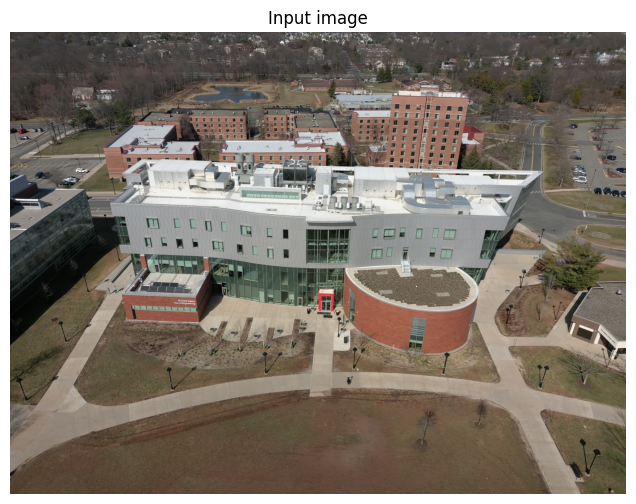

In [3]:
from google.colab import files

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

bgr = cv2.imread(img_path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

H, W = rgb.shape[:2]

plt.figure(figsize=(8,6))
plt.imshow(rgb)
plt.title("Input image")
plt.axis("off")
plt.show()


In [7]:
from segment_anything import SamPredictor
import gc, torch

predictor = SamPredictor(sam)
predictor.set_image(rgb)

H, W = rgb.shape[:2]
glass_mask = np.zeros((H, W), dtype=bool)

# Define a grid of vertical boxes (coarse, on purpose)
num_boxes = 12
box_width = W // num_boxes

for i in range(num_boxes):
    x0 = i * box_width
    x1 = min((i+1) * box_width, W)
    y0 = int(0.20 * H)
    y1 = int(0.75 * H)

    box = np.array([[x0, y0, x1, y1]])
    masks, scores, _ = predictor.predict(box=box, multimask_output=False)
    glass_mask |= masks[0]

# Free GPU cache
torch.cuda.empty_cache()
gc.collect()


677

In [10]:
roof_mask = np.zeros((H, W), dtype=bool)
roof_mask[:int(0.18 * H), :] = True

ground_mask = np.zeros((H, W), dtype=bool)
ground_mask[int(0.80 * H):, :] = True

facade_mask = (~glass_mask) & (~roof_mask) & (~ground_mask)


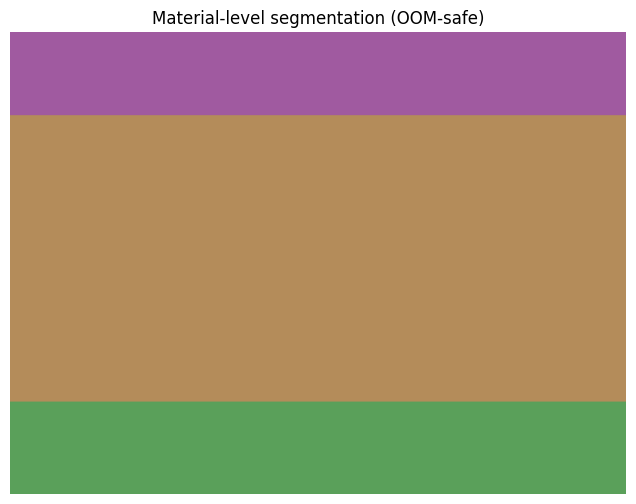

In [11]:
viz = rgb.copy()

viz[facade_mask] = [180, 140, 90]   # facade
viz[glass_mask]  = [70, 200, 255]   # glass
viz[roof_mask]   = [160, 90, 160]   # roof
viz[ground_mask] = [90, 160, 90]    # ground

plt.figure(figsize=(9,6))
plt.imshow(viz)
plt.axis("off")
plt.title("Material-level segmentation (OOM-safe)")
plt.show()


In [12]:
# Downscale aggressively
scale = 0.5
rgb_small = cv2.resize(rgb, None, fx=scale, fy=scale)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=16,        # ↓↓↓ critical
    pred_iou_thresh=0.88,
    stability_score_thresh=0.92,
    crop_n_layers=0,           # ❗ disables memory explosion
    min_mask_region_area=800
)

masks = mask_generator.generate(rgb_small)


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.15 GiB. GPU 0 has a total capacity of 14.74 GiB of which 1.77 GiB is free. Process 4552 has 12.96 GiB memory in use. Of the allocated memory 10.64 GiB is allocated by PyTorch, and 2.20 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [8]:
masks = mask_generator.generate(rgb)

print("Total masks:", len(masks))


OutOfMemoryError: CUDA out of memory. Tried to allocate 3.98 GiB. GPU 0 has a total capacity of 14.74 GiB of which 2.52 GiB is free. Process 4552 has 12.21 GiB memory in use. Of the allocated memory 9.83 GiB is allocated by PyTorch, and 2.26 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [9]:
# Initialize regions
glass_mask  = np.zeros((H, W), dtype=bool)
roof_mask   = np.zeros((H, W), dtype=bool)
ground_mask = np.zeros((H, W), dtype=bool)

# Geometry priors
roof_mask[:int(0.18 * H), :] = True
ground_mask[int(0.80 * H):, :] = True

# Collect candidate glass masks
for m in masks:
    seg = m["segmentation"]
    area = seg.sum()

    if area < 500:
        continue

    # Glass tends to be:
    # - vertical-ish
    # - not roof
    # - not ground
    overlap_roof = (seg & roof_mask).sum() / area
    overlap_ground = (seg & ground_mask).sum() / area

    if overlap_roof < 0.2 and overlap_ground < 0.2:
        # shape heuristic: taller than wide
        ys, xs = np.where(seg)
        h = ys.max() - ys.min() + 1
        w = xs.max() - xs.min() + 1

        if h > w * 1.2:
            glass_mask |= seg


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [ ]:
facade_mask = (~glass_mask) & (~roof_mask) & (~ground_mask)


In [ ]:
kernel = np.ones((7,7), np.uint8)
glass_mask  = cv2.dilate(glass_mask.astype(np.uint8), kernel) > 0
facade_mask = cv2.morphologyEx(facade_mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel) > 0


In [ ]:
viz = rgb.copy()

viz[facade_mask] = [180, 140, 90]    # facade (brownish)
viz[glass_mask]  = [70, 200, 255]    # glass (cyan)
viz[roof_mask]   = [160, 90, 160]    # roof (purple)
viz[ground_mask] = [90, 160, 90]     # ground (green)

plt.figure(figsize=(9,6))
plt.imshow(viz)
plt.axis("off")
plt.title("Material-level segmentation (presentation output)")
plt.show()
